# SpaceX Falcon 9 – Machine Learning Prediction
Predict whether the Falcon 9 first stage will land successfully using Logistic Regression, SVM, Decision Tree and KNN, tuned with GridSearchCV.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

In [2]:
def plot_confusion_matrix(y, y_predict):
    cm = confusion_matrix(y, y_predict)
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, ax=ax)
    ax.set_xlabel('Predicted labels'); ax.set_ylabel('True labels')
    ax.set_title('Confusion Matrix')
    ax.xaxis.set_ticklabels(['did not land', 'land']); ax.yaxis.set_ticklabels(['did not land', 'landed'])
    plt.show()

In [3]:
import os
import pandas as pd
# use the local copy in data/ if present, otherwise download from IBM Skills Network
data = pd.read_csv("data/dataset_part_2.csv" if os.path.exists("data/dataset_part_2.csv") else "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")
data.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


In [4]:
# one-hot encoded features (same steps as the EDA notebook, output dataset_part_3.csv)
features = data[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
X = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial']).astype('float64')
X.shape

(90, 80)

## Task 1: Create a NumPy array from the column Class

In [5]:
Y = data['Class'].to_numpy()

## Task 2: Standardize the data

In [6]:
transform = preprocessing.StandardScaler()
X = transform.fit_transform(X)

## Task 3: Split the data into training and test data

In [7]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
print('Test sample size:', Y_test.shape[0])

Test sample size: 18


## Task 4–5: Logistic Regression

tuned hyperparameters : {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
validation accuracy : 0.8214285714285714
test accuracy : 0.8333333333333334


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logi

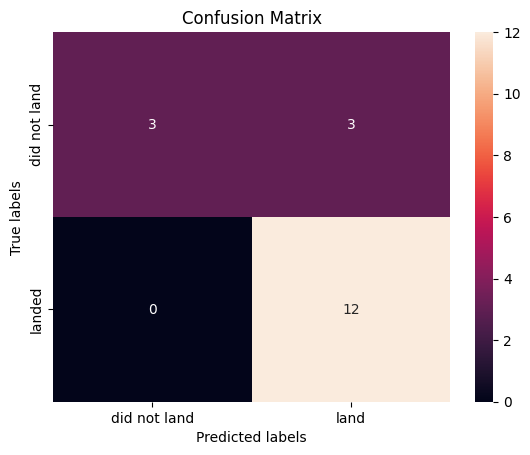

In [8]:
parameters = {'C': [0.01, 0.1, 1], 'penalty': ['l2'], 'solver': ['lbfgs']}
logreg_cv = GridSearchCV(LogisticRegression(), parameters, cv=10).fit(X_train, Y_train)
print('tuned hyperparameters :', logreg_cv.best_params_)
print('validation accuracy :', logreg_cv.best_score_)
print('test accuracy :', logreg_cv.score(X_test, Y_test))
plot_confusion_matrix(Y_test, logreg_cv.predict(X_test))

## Task 6–7: Support Vector Machine

tuned hyperparameters : {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
validation accuracy : 0.8482142857142858
test accuracy : 0.8333333333333334


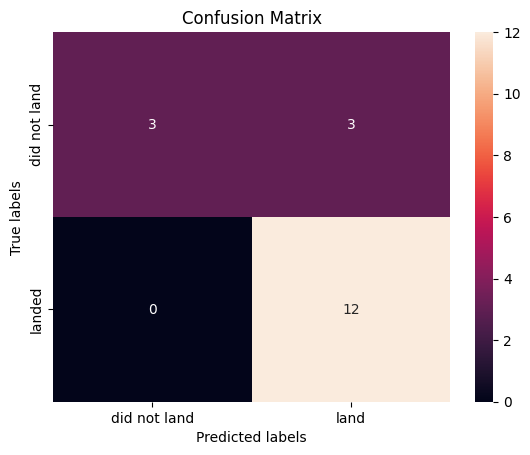

In [9]:
parameters = {'kernel': ('linear', 'rbf', 'poly', 'rbf', 'sigmoid'), 'C': np.logspace(-3, 3, 5), 'gamma': np.logspace(-3, 3, 5)}
svm_cv = GridSearchCV(SVC(), parameters, cv=10).fit(X_train, Y_train)
print('tuned hyperparameters :', svm_cv.best_params_)
print('validation accuracy :', svm_cv.best_score_)
print('test accuracy :', svm_cv.score(X_test, Y_test))
plot_confusion_matrix(Y_test, svm_cv.predict(X_test))

## Task 8–9: Decision Tree

tuned hyperparameters : {'criterion': 'gini', 'max_depth': 2, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'best'}
validation accuracy : 0.8482142857142858
test accuracy : 0.8333333333333334


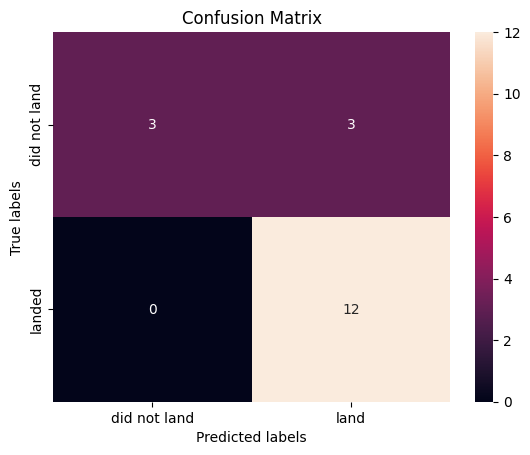

In [10]:
parameters = {'criterion': ['gini', 'entropy'], 'splitter': ['best', 'random'], 'max_depth': [2*n for n in range(1, 10)],
              'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, 4], 'min_samples_split': [2, 5, 10]}
tree_cv = GridSearchCV(DecisionTreeClassifier(random_state=0), parameters, cv=10).fit(X_train, Y_train)
print('tuned hyperparameters :', tree_cv.best_params_)
print('validation accuracy :', tree_cv.best_score_)
print('test accuracy :', tree_cv.score(X_test, Y_test))
plot_confusion_matrix(Y_test, tree_cv.predict(X_test))

## Task 10–11: K-Nearest Neighbors

tuned hyperparameters : {'algorithm': 'auto', 'n_neighbors': 6, 'p': 1}
validation accuracy : 0.8339285714285714
test accuracy : 0.8333333333333334


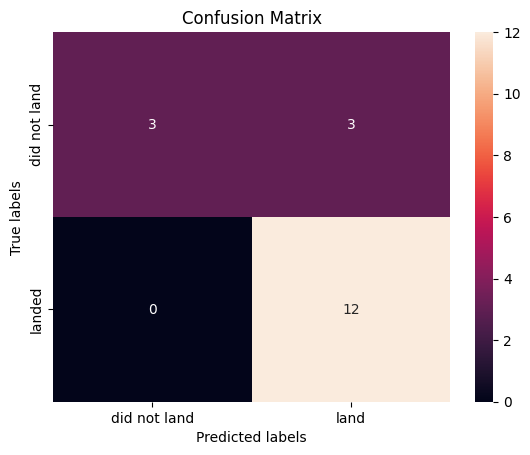

In [11]:
parameters = {'n_neighbors': list(range(1, 11)), 'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'], 'p': [1, 2]}
knn_cv = GridSearchCV(KNeighborsClassifier(), parameters, cv=10).fit(X_train, Y_train)
print('tuned hyperparameters :', knn_cv.best_params_)
print('validation accuracy :', knn_cv.best_score_)
print('test accuracy :', knn_cv.score(X_test, Y_test))
plot_confusion_matrix(Y_test, knn_cv.predict(X_test))

## Task 12: Find the method that performs best

In [12]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'SVM', 'Decision Tree', 'KNN'],
    'Validation accuracy': [logreg_cv.best_score_, svm_cv.best_score_, tree_cv.best_score_, knn_cv.best_score_],
    'Test accuracy': [logreg_cv.score(X_test, Y_test), svm_cv.score(X_test, Y_test), tree_cv.score(X_test, Y_test), knn_cv.score(X_test, Y_test)]})
results.sort_values('Validation accuracy', ascending=False)

,Model,Validation accuracy,Test accuracy
1,SVM,0.848214,0.833333
2,Decision Tree,0.848214,0.833333
3,KNN,0.833929,0.833333
0,Logistic Regression,0.821429,0.833333


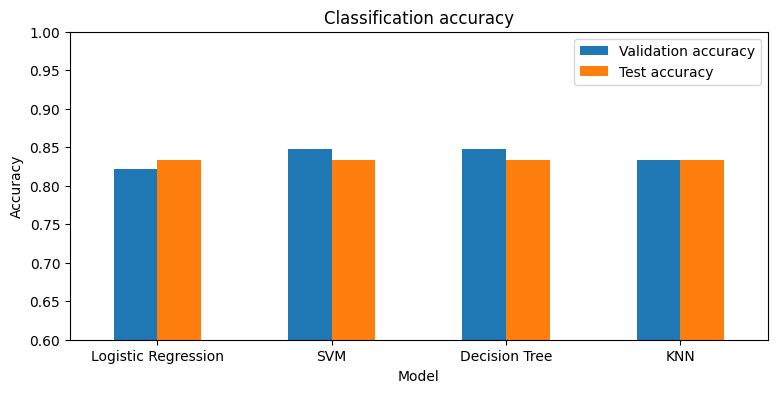

In [13]:
results.set_index('Model').plot(kind='bar', figsize=(9, 4), ylim=(0.6, 1.0), rot=0)
plt.ylabel('Accuracy'); plt.title('Classification accuracy'); plt.show()

All four models reach the same test accuracy (83.33%). SVM and Decision Tree have the highest validation accuracy. The confusion matrices show the models can distinguish the classes; the main problem is false positives (unsuccessful landings predicted as successful).